# 02 · Data cleaning & validation
Every cleaning decision is **documented with evidence**. Principle: *investigate, don't auto-drop.* Valid high-value orders are kept.

In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.ticker as mtick
import seaborn as sns
import olist
olist.setup_plots()
pd.options.display.float_format = "{:,.2f}".format
pd.options.display.max_columns = 40
BRL = mtick.FuncFormatter(lambda x, p: f"R${x/1e6:.1f}M" if abs(x) >= 1e6 else f"R${x/1e3:.0f}k")

In [2]:
t = olist.load_raw()
o_raw = t["orders"]

## 1 · Timestamp parsing

In [3]:
parse_fail = {}
for c in olist.ORDER_DATE_COLS:
    parsed = pd.to_datetime(o_raw[c], errors="coerce")
    parse_fail[c] = {"null_in_raw": int(o_raw[c].isna().sum()), "parse_failures": int(parsed.isna().sum() - o_raw[c].isna().sum())}
pd.DataFrame(parse_fail).T

,null_in_raw,parse_failures
order_purchase_timestamp,0,0
order_approved_at,160,0
order_delivered_carrier_date,1783,0
order_delivered_customer_date,2965,0
order_estimated_delivery_date,0,0


**No parse failures** — every non-null timestamp is valid. Nulls are genuine (an order not yet approved/shipped/delivered).

## 2 · Missing values by column (and why)

In [4]:
o = olist.clean_orders(o_raw)
miss = o.groupby("order_status")[["order_approved_at","order_delivered_carrier_date","order_delivered_customer_date"]].apply(lambda d: d.isna().sum())
miss["orders"] = o.groupby("order_status").size()
miss

,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,orders
order_status,,,,
approved,0,2,2,2
canceled,141,550,619,625
created,5,5,5,5
delivered,14,2,8,96478
invoiced,0,314,314,314
processing,0,301,301,301
shipped,0,0,1107,1107
unavailable,0,609,609,609


In [5]:
print("'delivered' but NO delivery date :", ((o.order_status=="delivered") & o.order_delivered_customer_date.isna()).sum())
print("'canceled'  but HAS a delivery date:", ((o.order_status=="canceled") & o.order_delivered_customer_date.notna()).sum())
print("delivered orders missing approval  :", ((o.order_status=="delivered") & o.order_approved_at.isna()).sum())

'delivered' but NO delivery date : 8
'canceled'  but HAS a delivery date: 6
delivered orders missing approval  : 14


**Decision**
- Nulls in delivery columns are explained by order status → **not dropped**.
- The 8 `delivered` orders with no delivery date can't contribute to delivery-time / delay analysis → flagged via `is_delivered = status=='delivered' AND delivery_date NOT NULL`. They remain in revenue totals.
- 6 canceled orders with a delivery date are left as-is: all revenue/delivery analyses filter on `delivered`, so they are excluded automatically.

## 3 · Impossible / suspicious values

In [6]:
i, p, pay, prod = t["items"], t["payments"], t["payments"], t["products"]
checks = {
 "items: price <= 0": int((t["items"].price <= 0).sum()),
 "items: freight < 0": int((t["items"].freight_value < 0).sum()),
 "items: freight == 0": int((t["items"].freight_value == 0).sum()),
 "payments: payment_value == 0": int((t["payments"].payment_value == 0).sum()),
 "payments: installments == 0": int((t["payments"].payment_installments == 0).sum()),
 "payments: type 'not_defined'": int((t["payments"].payment_type == "not_defined").sum()),
 "products: weight == 0": int((prod.product_weight_g == 0).sum()),
 "products: null category": int(prod.product_category_name.isna().sum()),
 "orders: delivered BEFORE purchase": int((o.order_delivered_customer_date < o.order_purchase_timestamp).sum()),
 "orders: approved BEFORE purchase": int((o.order_approved_at < o.order_purchase_timestamp).sum()),
 "orders: carrier pickup BEFORE purchase": int((o.order_delivered_carrier_date < o.order_purchase_timestamp).sum()),
 "orders: delivered BEFORE carrier pickup": int((o.order_delivered_customer_date < o.order_delivered_carrier_date).sum()),
 "reviews: score outside 1-5": int((~t["reviews"].review_score.between(1,5)).sum()),
}
pd.Series(checks, name="rows").to_frame()

,rows
items: price <= 0,0
items: freight < 0,0
items: freight == 0,383
payments: payment_value == 0,9
payments: installments == 0,2
payments: type 'not_defined',3
products: weight == 0,4
products: null category,610
orders: delivered BEFORE purchase,0
orders: approved BEFORE purchase,0


**Decisions**
- **Zero** negative/zero prices and no delivered-before-purchase rows: the core money and date fields are sound.
- `payment_value == 0` (9 rows: 6 vouchers + 3 `not_defined`) → kept; harmless for order totals but **excluded from the payment-type test** (`not_defined`, n=3).
- A small number of orders have carrier pickup/approval timestamps that look out of order → not used in any metric, so left untouched but documented.
- `freight == 0` is plausible (free shipping) → kept.

## 4 · Reviews: duplicates and coverage

In [7]:
r = t["reviews"]
print(f"review rows: {len(r):,} | unique review_id: {r.review_id.nunique():,} | unique orders reviewed: {r.order_id.nunique():,}")
multi = r.groupby("order_id").size()
print(f"orders with >1 review: {(multi>1).sum():,}")
print(f"orders with NO review: {(~o_raw.order_id.isin(r.order_id)).sum():,}")
print("\nreview_score distribution (%):"); print((100*r.review_score.value_counts(normalize=True).sort_index()).round(1).to_string())

review rows: 99,224 | unique review_id: 98,410 | unique orders reviewed: 98,673


orders with >1 review: 547


orders with NO review: 768

review_score distribution (%):
review_score
1   11.50
2    3.20
3    8.20
4   19.30
5   57.80


**Decision:** one review per order — keep the **most recent** (by `review_answer_timestamp`), so each order has an integer 1–5 score. Orders with no review (≈0.8%) simply have no score and drop out of review analyses. (The SQL layer averages duplicates instead; the difference touches only 547 orders and does not change any conclusion.)

## 5 · Product categories

In [8]:
cat = olist.category_table(t)
untranslated = cat[cat.product_category_name.notna() & cat.product_category_name_english.isna()].product_category_name.value_counts()
print("Categories with no English translation:"); print(untranslated.to_string())
print("\nProducts with NULL category:", cat.product_category_name.isna().sum())

Categories with no English translation:
product_category_name
portateis_cozinha_e_preparadores_de_alimentos    10
pc_gamer                                          3

Products with NULL category: 610


**Decision:** NULL category → label `unknown` (not dropped; they still have revenue). Two untranslated names (`pc_gamer`, `portateis_cozinha_e_preparadores_de_alimentos`) fall back to the Portuguese name — they are tiny.

## 6 · Join cardinality — the fan-out trap (why we aggregate first)

In [9]:
items, pay = t["items"], t["payments"]
naive = o_raw[["order_id"]].merge(items[["order_id","price"]], on="order_id").merge(pay[["order_id","payment_value"]], on="order_id")
true_rev = items.price.sum()
naive_rev = naive.price.sum()
print(f"True item revenue (items table)      : R$ {true_rev:,.0f}")
print(f"Naive items JOIN payments, SUM(price): R$ {naive_rev:,.0f}   ({100*(naive_rev/true_rev-1):+.1f}% inflated)")

True item revenue (items table)      : R$ 13,591,644
Naive items JOIN payments, SUM(price): R$ 14,209,115   (+4.5% inflated)


Joining `order_items` to `payments` directly repeats each item row once per payment row and **inflates revenue**. `olist.build_order_facts()` aggregates items, payments and reviews to *one row per order first*, then joins.

In [10]:
f = olist.build_order_facts(t)
assert f.order_id.is_unique and len(f) == len(o_raw)
d = f[f.is_delivered]
print("order_facts rows:", len(f), "| delivered & analysable:", len(d))
print(f"Delivered item revenue (order_facts): R$ {d.item_revenue.sum():,.2f}")
chk = pd.read_csv("../reports/sql_results/q02_monthly_item_revenue.csv")
print(f"Delivered item revenue (SQL q02)    : R$ {chk.item_revenue.sum():,.2f}   <- should match closely")

order_facts rows: 99441 | delivered & analysable: 96470
Delivered item revenue (order_facts): R$ 13,220,248.93
Delivered item revenue (SQL q02)    : R$ 13,221,498.11   <- should match closely


The pandas and SQL pipelines agree (tiny difference = the 8 delivered orders with no delivery date, which SQL's q02 keeps). Two independent implementations reconciling is the strongest check on the join logic.

## 7 · Does money reconcile? (items + freight vs payments)

In [11]:
both = f[f.item_revenue.notna() & f.payment_value.notna()]
diff = (both.payment_value - both.total_value)
print(f"orders compared: {len(both):,}")
print(f"|payment - (items+freight)| <= R$1 : {(diff.abs()<=1).mean()*100:.2f}%")
print(f"total paid / total expected        : {both.payment_value.sum()/both.total_value.sum():.4f}")
print("\nDifferences > R$1 (n=%d) - quantiles:" % (diff.abs()>1).sum()); print(diff[diff.abs()>1].describe().round(2).to_string())

orders compared: 98,665
|payment - (items+freight)| <= R$1 : 99.75%
total paid / total expected        : 1.0002

Differences > R$1 (n=249) - quantiles:
count   249.00
mean     11.51
std      19.35
min     -51.62
25%       3.29
50%       6.98
75%      14.12
max     182.81


99.7% of orders reconcile to within R$1. The remainder is small (median gap ≈ R$7) and plausibly instalment interest or fees on credit purchases (a hypothesis, not verified here). **Definitions are therefore kept separate:** `item_revenue` (price only), `total_value` (price + freight) and `payment_value` (cash paid) are *never* used interchangeably.

## 8 · Outliers — inspect, don't delete

0.50       86.50
0.90      269.00
0.99      990.00
1.00    2,258.00
1.00   13,440.00


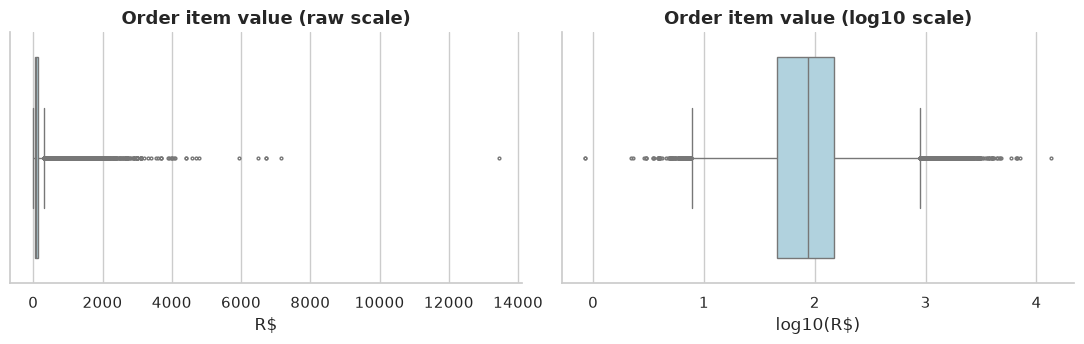

In [12]:
d = f[f.is_delivered]
q = d.item_revenue.quantile([.5,.9,.99,.999,1]).rename("item_revenue")
print(q.to_string())
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
sns.boxplot(x=d.item_revenue, ax=axes[0], color="#a9d6e5", fliersize=2); axes[0].set_title("Order item value (raw scale)")
sns.boxplot(x=np.log10(d.item_revenue), ax=axes[1], color="#a9d6e5", fliersize=2); axes[1].set_title("Order item value (log10 scale)")
axes[0].set_xlabel("R$"); axes[1].set_xlabel("log10(R$)"); plt.tight_layout()

In [13]:
top = d.nlargest(5, "item_revenue")[["order_id","item_revenue","n_items","freight","customer_state"]]
top

,order_id,item_revenue,n_items,freight,customer_state
13390,03caa2c082116e1d31e67e9ae3700499,"13,440.00",8.00,224.08,RJ
66599,736e1922ae60d0d6a89247b851902527,"7,160.00",4.00,114.88,ES
22171,0812eb902a67711a1cb742b3cdaa65ae,"6,735.00",1.00,194.31,MS
28326,fefacc66af859508bf1a7934eab1e97f,"6,729.00",1.00,193.21,ES
3508,f5136e38d1a14a4dbd87dff67da82701,"6,499.00",1.00,227.66,SP


The largest orders (up to ~R$13k) are **single items or plausible multi-item baskets** at high prices, not data errors. **Decision: keep all outliers**; handle skew in analysis with medians, log scales and rank-based tests rather than deleting rows.

## 9 · Save analysis-ready table

In [14]:
olist.PROCESSED.mkdir(parents=True, exist_ok=True)
f.to_csv(olist.PROCESSED / "order_facts.csv.gz", index=False)
print("saved", olist.PROCESSED / "order_facts.csv.gz", f.shape)
f.head(3).T

saved /home/vishal-patel/Downloads/prep/data_analysis/data/processed/order_facts.csv.gz (99441, 27)


,0,1,2
order_id,e481f51cbdc54678b7cc49136f2d6af7,53cdb2fc8bc7dce0b6741e2150273451,47770eb9100c2d0c44946d9cf07ec65d
customer_id,9ef432eb6251297304e76186b10a928d,b0830fb4747a6c6d20dea0b8c802d7ef,41ce2a54c0b03bf3443c3d931a367089
order_status,delivered,delivered,delivered
order_purchase_timestamp,2017-10-02 10:56:33,2018-07-24 20:41:37,2018-08-08 08:38:49
order_approved_at,2017-10-02 11:07:15,2018-07-26 03:24:27,2018-08-08 08:55:23
order_delivered_carrier_date,2017-10-04 19:55:00,2018-07-26 14:31:00,2018-08-08 13:50:00
order_delivered_customer_date,2017-10-10 21:25:13,2018-08-07 15:27:45,2018-08-17 18:06:29
order_estimated_delivery_date,2017-10-18 00:00:00,2018-08-13 00:00:00,2018-09-04 00:00:00
purchase_month,2017-10,2018-07,2018-08
delivery_days,8.44,13.78,9.39


## Cleaning log (summary)
| # | Issue | Decision |
|---|-------|----------|
| 1 | Sparse 2016 & Sep–Oct 2018 | Excluded from *trend* analysis (window 2017-01 → 2018-08) |
| 2 | 8 `delivered` orders lack delivery date | `is_delivered` flag; excluded from delivery analysis only |
| 3 | `review_id` duplicated; 547 orders >1 review | Keep latest review per order |
| 4 | 610 products with NULL category; 2 untranslated | Label `unknown` / Portuguese fallback |
| 5 | `payment_type = not_defined` (n=3) | Kept in data, excluded from payment-type test |
| 6 | Item/payment fan-out when joined | Aggregate each table to order grain first |
| 7 | Extreme order values | Kept (valid); handled via medians / log / rank tests |
| 8 | `customer_id` is per-order | Use `customer_unique_id` for customer analysis |